In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler , MinMaxScaler, OneHotEncoder
from sklearn.metrics import accuracy_score,precision_score,f1_score,recall_score,confusion_matrix,classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
import warnings
warnings.filterwarnings("ignore",category=FutureWarning)

In [ ]:
cs=pd.read_csv("Customer Satisfaction.csv")
cs.head()

,id,Gender,Age,Travel Category,Travel Class,Distance Travelled,Departure/Arrival Rating,Booking Ease,Boarding Point,Food,Seat Comfort,Entertainment,Leg Room,Luggage Handling,Cleanliness,Departure Delay (min),Arrival Delay (min),Satisfaction
0,70172,Male,13,Personal Travel,Premium,414,4.0,3.0,1.0,5.0,5.0,5.0,NaN,4.0,5,25,18.0,dissatisfied
1,5047,Male,25,Official,Business,212,2.0,3.0,3.0,1.0,NaN,1.0,5.0,3.0,1,1,6.0,dissatisfied
2,110028,Female,26,Official,Business,1028,2.0,2.0,2.0,5.0,5.0,5.0,3.0,4.0,5,0,0.0,satisfied
3,24026,Female,25,Official,Business,506,5.0,5.0,5.0,NaN,2.0,2.0,5.0,3.0,2,11,9.0,dissatisfied
4,119299,Male,61,Official,Business,193,3.0,3.0,3.0,NaN,5.0,3.0,4.0,4.0,3,0,0.0,satisfied


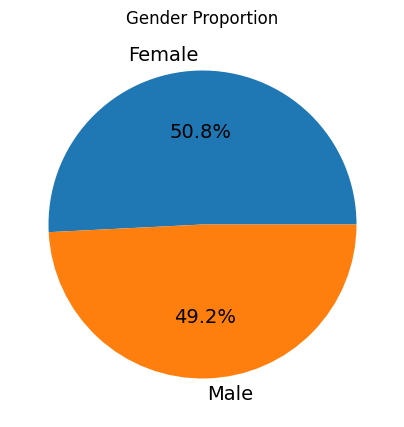

In [ ]:
#calculate gender counts
gender_counts=cs['Gender'].value_counts()
#plot pie chart for gender proportion
plt.figure(figsize=(5,5))
plt.pie(gender_counts,labels=gender_counts.index,autopct="%1.1f%%",textprops={'fontsize':14})
plt.title("Gender Proportion")
plt.show()

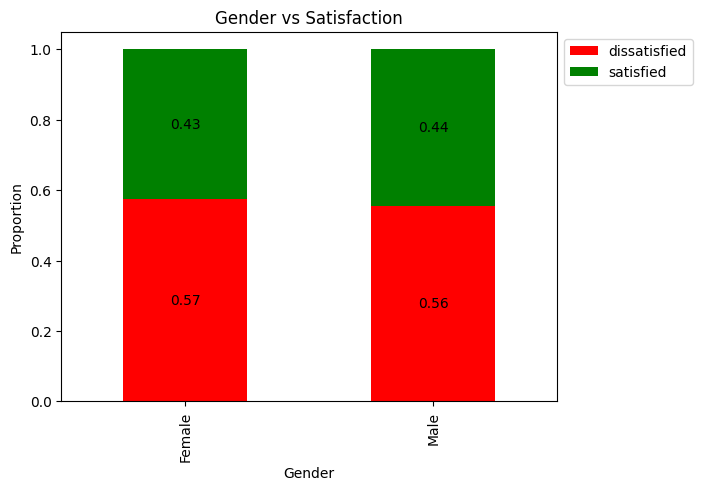

In [ ]:
#create cross tab for gender vs satisfaction
gender_sat=pd.crosstab(cs['Gender'],cs['Satisfaction'],normalize='index')
#plot stacked bar chart with cross table of gender vs satisfaction
fig,ax=plt.subplots()
gender_sat.plot(kind='bar',stacked=True,color=['red','green'],ax=ax)
for container in ax.containers:
    ax.bar_label(container,label_type='center',fmt="%.2f")
plt.title('Gender vs Satisfaction')
plt.xlabel('Gender')
plt.ylabel('Proportion')
plt.legend(bbox_to_anchor=(1,1,))
plt.show()

In [ ]:
#chi2 test for Gender vs Satisfaction
from scipy.stats import chi2_contingency
chi2,p_value,dof,expected=chi2_contingency(gender_sat)
print(f"Chi-square statistic: {chi2:.2f}")
print(f"p-value : {p_value:.2f}")

Chi-square statistic: 0.00
p-value : 1.00


In [ ]:
#calcuate mean age
age_mean=cs['Age'].mean()
print(f"Average Age: {age_mean:.1f}")
#calculate range of age
age_min=cs['Age'].min()
age_max=cs['Age'].max()
print(f"Min Age: {age_min}")
print(f"Max Age: {age_max}")
print(f"Range of Age: {age_max-age_min}")

Average Age: 39.4
Min Age: 7
Max Age: 85
Range of Age: 78


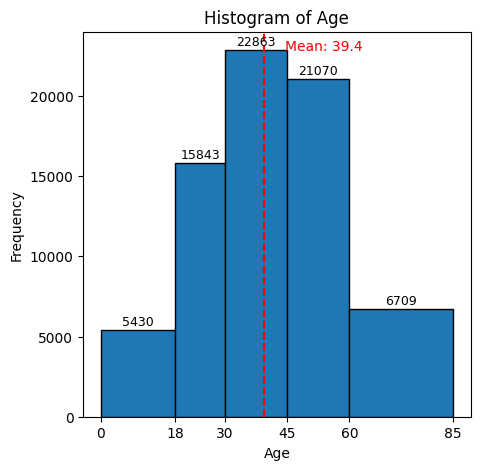

In [ ]:
#plot hisrogram for age
bin_edges=[0,18,30,45,60,85]
plt.figure(figsize=(5,5))
counts,edges,bars=plt.hist(cs['Age'],bins=bin_edges,edgecolor='black')
plt.title("Histogram of Age")
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.xticks(bin_edges)
plt.bar_label(bars,padding=1,size=9)
#plot mean line
plt.axvline(age_mean,color='red',linestyle='dashed')
plt.text(age_mean+5,max(counts)+5,f'Mean: {age_mean:.1f}',color='red')
plt.show()

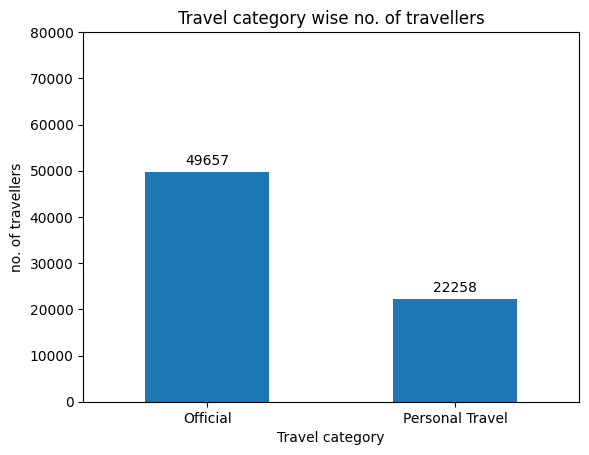

In [ ]:
#calculate travel category wise frequency
travel_cat=cs['Travel Category'].value_counts()
ax=travel_cat.plot(kind='bar')
for container in ax.containers:
    ax.bar_label(container,padding=3)
plt.title("Travel category wise no. of travellers")
plt.xticks(rotation=0)
plt.ylim(0,80000)
plt.xlabel("Travel category")
plt.ylabel("no. of travellers")
plt.show()

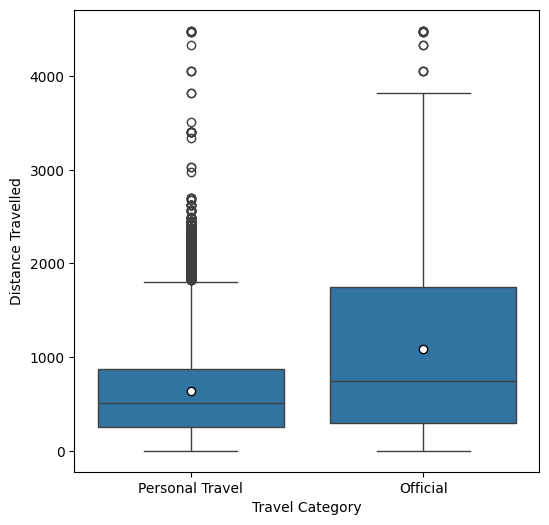

Travel Category
Official           1090.462916
Personal Travel     633.299398
Name: Distance Travelled, dtype: float64


In [ ]:
#plot box plot
plt.figure(figsize=(6,6))
sns.boxplot(data=cs,x='Travel Category',y='Distance Travelled',showmeans=True,meanprops={'marker':'o','markerfacecolor':'white','markeredgecolor':'black'})
plt.show()
#Average distance by travel category
print(cs.groupby('Travel Category')['Distance Travelled'].mean())

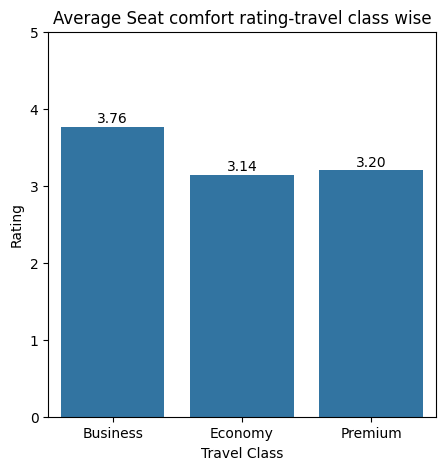

In [ ]:
#Average rating of seat comfort across travel classes
avg_seat_comf=cs.groupby('Travel Class')['Seat Comfort'].mean()
#plot bar chart for average seat comformt across travel class
plt.figure(figsize=(5,5))
ax=sns.barplot(x=avg_seat_comf.index,y=avg_seat_comf.values)
for container in ax.containers:
    ax.bar_label(container,padding=1,fmt="%.2f")
plt.title('Average Seat comfort rating-travel class wise')
plt.ylabel('Rating')
plt.ylim(0,5)
plt.show()

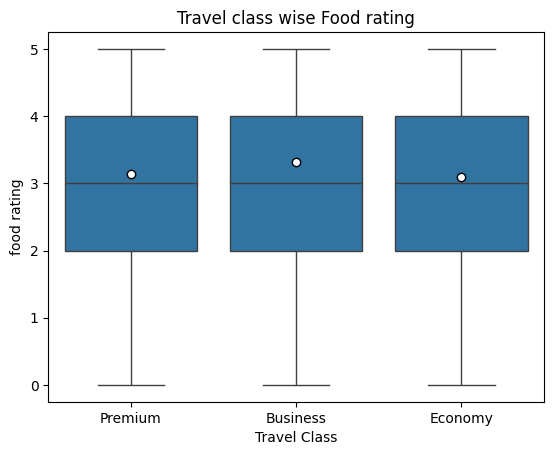

t-test for Business vs Eco-Food rating:
t-statistic:20.0592
p-value:0.0000
p-value is less than 0.05, null hypothesis is rejected and statistically significant difference


In [ ]:
#plot boxplot for Travel class wise food rating
sns.boxplot(data=cs,x=cs['Travel Class'],y=cs['Food'],showmeans=True,meanprops={'marker':'o','markerfacecolor':'white','markeredgecolor':'black'})
plt.ylabel('food rating')
plt.title('Travel class wise Food rating')
plt.show()
#copy business and economy travel class food rating in seperate dataframe
bus_food=cs[cs["Travel Class"]=="Business"]["Food"].dropna()
eco_food=cs[cs["Travel Class"]=="Economy"]["Food"].dropna()
#2-sample t-test for food rating of Business and Eco class
t_stat,p_value=stats.ttest_ind(bus_food,eco_food,equal_var=False)
print('t-test for Business vs Eco-Food rating:')
print(f"t-statistic:{t_stat:.4f}")
print(f"p-value:{p_value:.4f}")
alpha=0.05
if(p_value<alpha):
    print(f"p-value is less than {alpha}, null hypothesis is rejected and statistically significant difference")
else:
     print(f"p-value is greather than {alpha}, null hypothesis is accepted and difference is not statistically significant")

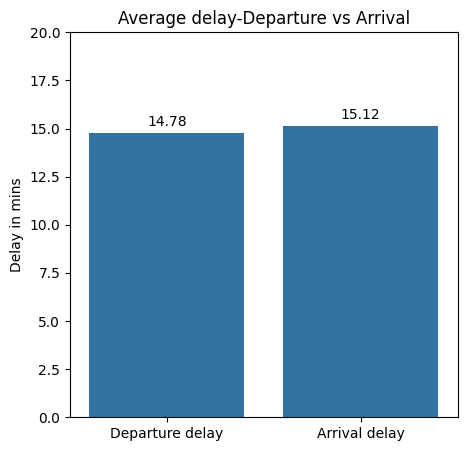

In [ ]:
#average departure and arrival delay
avg_dep_delay=cs['Departure Delay (min)'].mean()
avg_arr_delay=cs['Arrival Delay (min)'].mean()
#bar plot for departure and arrival delay
delay_metrics=['Departure delay','Arrival delay']
delay_values=[avg_dep_delay,avg_arr_delay]
plt.figure(figsize=(5,5))
ax=sns.barplot(x=delay_metrics,y=delay_values)
plt.title("Average delay-Departure vs Arrival")
for container in ax.containers:
    ax.bar_label(container,padding=3,fmt="%.2f")
plt.ylabel('Delay in mins')
plt.ylim(0,20)
plt.show()

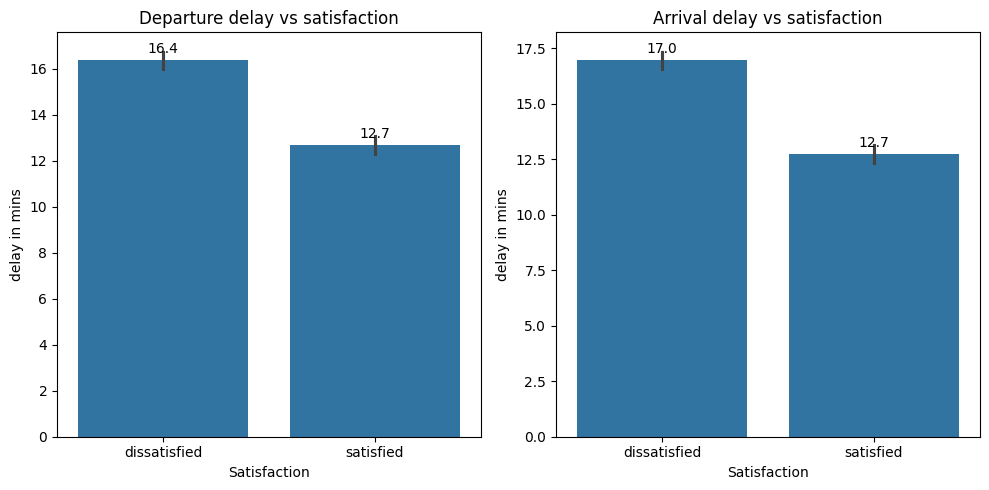

--- Departure Delays vs Satisfaction ---
t-statistic: -12.8955
p-value: 0.0000
--- Arrival Delays vs Satisfaction ---
t-statistic: -14.5316
p-value: 0.0000


In [ ]:
#bar chart for average departure & arrival delay vs satisfaction
fig,axes=plt.subplots(1,2,figsize=(10,5))
sns.barplot(data=cs,x="Satisfaction",y="Departure Delay (min)",ax=axes[0])
axes[0].set_title("Departure delay vs satisfaction")
axes[0].set_ylabel("delay in mins")
sns.barplot(data=cs,x="Satisfaction",y="Arrival Delay (min)",ax=axes[1])
axes[1].set_title("Arrival delay vs satisfaction")
axes[1].set_ylabel("delay in mins")
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f', padding=3)
plt.tight_layout()
plt.show()
#seperate dataframe for departure & arrival vs satisfied & not satisfied
clean_cs=cs.dropna(subset=['Departure Delay (min)','Arrival Delay (min)'])
satisfied_dep=clean_cs[clean_cs['Satisfaction']=='satisfied']['Departure Delay (min)']
unsatisfied_dep=clean_cs[clean_cs['Satisfaction']!='satisfied']['Departure Delay (min)']
satisfied_arr=clean_cs[clean_cs['Satisfaction']=='satisfied']['Arrival Delay (min)']
unsatisfied_arr=clean_cs[clean_cs['Satisfaction']!='satisfied']['Arrival Delay (min)']
#t-test for arrival and departure vs satisfied & not satisfied
t_stat_dep,p_val_dep=stats.ttest_ind(satisfied_dep,unsatisfied_dep,equal_var='False')
t_stat_arr,p_val_arr=stats.ttest_ind(satisfied_arr,unsatisfied_arr,equal_var='False')
print("--- Departure Delays vs Satisfaction ---")
print(f"t-statistic: {t_stat_dep:.4f}")
print(f"p-value: {p_val_dep:.4f}")
print("--- Arrival Delays vs Satisfaction ---")
print(f"t-statistic: {t_stat_arr:.4f}")
print(f"p-value: {p_val_arr:.4f}")

In [ ]:
#Columns with missing values
cs.isnull().sum()

,0
id,0
Gender,0
Age,0
Travel Category,0
Travel Class,4300
Distance Travelled,0
Departure/Arrival Rating,8252
Booking Ease,8448
Boarding Point,6384
Food,9690


In [ ]:
#arrival delay missing values imputing wiht median
cs['Arrival Delay (min)']=cs['Arrival Delay (min)'].fillna(cs['Arrival Delay (min)'].median())
#impute missing values of other categorical columns with mode
col_mod_imp=['Travel Class','Departure/Arrival Rating','Booking Ease','Boarding Point','Food','Seat Comfort','Entertainment','Leg Room','Luggage Handling']
for col in col_mod_imp:
    col_mode=cs[col].mode()[0]
    cs[col]=cs[col].fillna(col_mode)
cs.isnull().sum()

,0
id,0
Gender,0
Age,0
Travel Category,0
Travel Class,0
Distance Travelled,0
Departure/Arrival Rating,0
Booking Ease,0
Boarding Point,0
Food,0


In [ ]:
cs.dtypes

,0
id,int64
Gender,object
Age,int64
Travel Category,object
Travel Class,object
Distance Travelled,int64
Departure/Arrival Rating,float64
Booking Ease,float64
Boarding Point,float64
Food,float64


In [ ]:
#binary encoding Satisfaction column
cs['Satisfaction']=cs['Satisfaction'].replace({'satisfied':1,'dissatisfied':0})
#one hot encoding categorical columns
cat_cols=['Gender','Travel Category','Travel Class']
cs_encoded=pd.get_dummies(cs,columns=cat_cols,drop_first=True,dtype=int)
cs_encoded.dtypes

,0
id,int64
Age,int64
Distance Travelled,int64
Departure/Arrival Rating,float64
Booking Ease,float64
Boarding Point,float64
Food,float64
Seat Comfort,float64
Entertainment,float64
Leg Room,float64


In [ ]:
#calculate iqr, outliers and percentage of outliers
num_cols=['Distance Travelled','Departure Delay (min)','Arrival Delay (min)']
for col in num_cols:
    q1=cs_encoded[col].quantile(0.25)
    q3=cs_encoded[col].quantile(0.75)
    iqr=q3-q1
    lb=q1-1.5*iqr
    ub=q3+1.5*iqr
    outliers=cs_encoded[(cs_encoded[col]<lb)|(cs_encoded[col]>ub)]
    p_outliers=(len(outliers)/len(cs_encoded))*100
    print(f"{col}:{p_outliers:.2f}% outliers")

Distance Travelled:3.47% outliers
Departure Delay (min):13.93% outliers
Arrival Delay (min):13.36% outliers


In [ ]:
#remove outliers
cs_encoded=cs_encoded[(cs_encoded['Distance Travelled']>=0)&(cs_encoded['Distance Travelled']<=3165)]
cs_encoded['Distance Travelled'].describe()

,Distance Travelled
count,69421.000000
mean,861.164504
std,796.975021
min,0.000000
25%,266.000000
50%,592.000000
75%,1307.000000
max,3165.000000


In [ ]:
#create total delay column with departure delay and arrival delay
cs_encoded['total_delay']=cs_encoded['Departure Delay (min)']+cs_encoded['Arrival Delay (min)']
cs_encoded.head()

,id,Age,Distance Travelled,Departure/Arrival Rating,Booking Ease,Boarding Point,Food,Seat Comfort,Entertainment,Leg Room,Luggage Handling,Cleanliness,Departure Delay (min),Arrival Delay (min),Satisfaction,Gender_Male,Travel Category_Personal Travel,Travel Class_Economy,Travel Class_Premium,total_delay
0,70172,13,414,4.0,3.0,1.0,5.0,5.0,5.0,4.0,4.0,5,25,18.0,0,1,1,0,1,43.0
1,5047,25,212,2.0,3.0,3.0,1.0,4.0,1.0,5.0,3.0,1,1,6.0,0,1,0,0,0,7.0
2,110028,26,1028,2.0,2.0,2.0,5.0,5.0,5.0,3.0,4.0,5,0,0.0,1,0,0,0,0,0.0
3,24026,25,506,5.0,5.0,5.0,4.0,2.0,2.0,5.0,3.0,2,11,9.0,0,0,0,0,0,20.0
4,119299,61,193,3.0,3.0,3.0,4.0,5.0,3.0,4.0,4.0,3,0,0.0,1,1,0,0,0,0.0


In [ ]:
#Min max scaling for departure delay , arrival delay , total delay and distance travelled and age
cols_to_scale=['Departure Delay (min)','Arrival Delay (min)','total_delay','Distance Travelled','Age']
scaler=MinMaxScaler()
cs_encoded[cols_to_scale]=scaler.fit_transform(cs_encoded[cols_to_scale])
cs_encoded.head()

,id,Age,Distance Travelled,Departure/Arrival Rating,Booking Ease,Boarding Point,Food,Seat Comfort,Entertainment,Leg Room,Luggage Handling,Cleanliness,Departure Delay (min),Arrival Delay (min),Satisfaction,Gender_Male,Travel Category_Personal Travel,Travel Class_Economy,Travel Class_Premium,total_delay
0,70172,0.076923,0.130806,4.0,3.0,1.0,5.0,5.0,5.0,4.0,4.0,5,0.019157,0.014063,0,1,1,0,1,0.016634
1,5047,0.230769,0.066983,2.0,3.0,3.0,1.0,4.0,1.0,5.0,3.0,1,0.000766,0.004688,0,1,0,0,0,0.002708
2,110028,0.243590,0.324803,2.0,2.0,2.0,5.0,5.0,5.0,3.0,4.0,5,0.000000,0.000000,1,0,0,0,0,0.000000
3,24026,0.230769,0.159874,5.0,5.0,5.0,4.0,2.0,2.0,5.0,3.0,2,0.008429,0.007031,0,0,0,0,0,0.007737
4,119299,0.692308,0.060979,3.0,3.0,3.0,4.0,5.0,3.0,4.0,4.0,3,0.000000,0.000000,1,1,0,0,0,0.000000


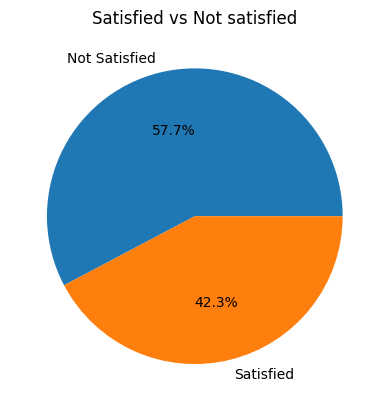

In [ ]:
#pie chart for satisfaction counts
sat_counts=cs_encoded['Satisfaction'].value_counts()
plt.pie(sat_counts,labels=['Not Satisfied','Satisfied'],autopct='%1.1f%%')
plt.title("Satisfied vs Not satisfied")
plt.show()

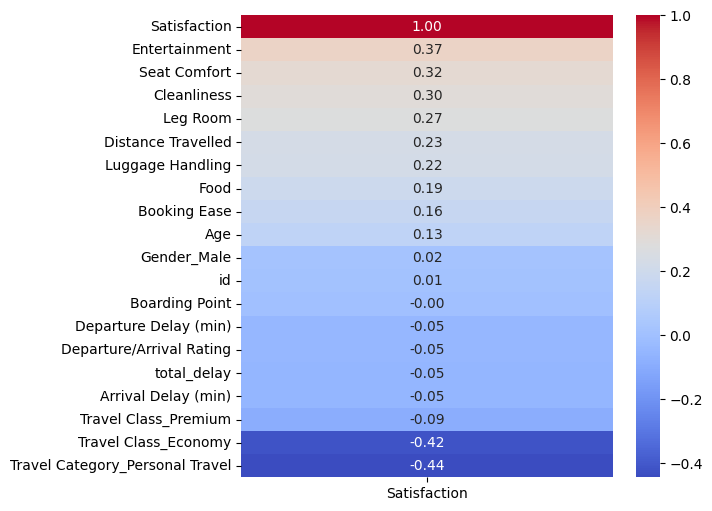

In [ ]:
#correlation matrix for satisfaction vs other columns
corr_matrix=cs_encoded.corr()
sat_corr = corr_matrix[['Satisfaction']].sort_values(by='Satisfaction', ascending=False)
#heatmap for satisfaction vs other columns
plt.figure(figsize=(6,6))
sns.heatmap(sat_corr,annot=True,cmap='coolwarm',fmt='.2f',cbar=True)
plt.show()

In [ ]:
y=cs_encoded['Satisfaction']
x=cs_encoded.drop(columns=['Satisfaction','id'])
x

,Age,Distance Travelled,Departure/Arrival Rating,Booking Ease,Boarding Point,Food,Seat Comfort,Entertainment,Leg Room,Luggage Handling,Cleanliness,Departure Delay (min),Arrival Delay (min),Gender_Male,Travel Category_Personal Travel,Travel Class_Economy,Travel Class_Premium,total_delay
0,0.076923,0.130806,4.0,3.0,1.0,5.0,5.0,5.0,4.0,4.0,5,0.019157,0.014063,1,1,0,1,0.016634
1,0.230769,0.066983,2.0,3.0,3.0,1.0,4.0,1.0,5.0,3.0,1,0.000766,0.004688,1,0,0,0,0.002708
2,0.243590,0.324803,2.0,2.0,2.0,5.0,5.0,5.0,3.0,4.0,5,0.000000,0.000000,0,0,0,0,0.000000
3,0.230769,0.159874,5.0,5.0,5.0,4.0,2.0,2.0,5.0,3.0,2,0.008429,0.007031,0,0,0,0,0.007737
4,0.692308,0.060979,3.0,3.0,3.0,4.0,5.0,3.0,4.0,4.0,3,0.000000,0.000000,1,0,0,0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71910,0.705128,0.096051,4.0,1.0,2.0,2.0,5.0,2.0,2.0,5.0,2,0.006130,0.000000,1,0,0,0,0.003095
71911,0.384615,0.048341,5.0,2.0,3.0,4.0,4.0,4.0,1.0,1.0,4,0.000766,0.000000,0,0,1,0,0.000387
71912,0.320513,0.091311,5.0,5.0,3.0,4.0,3.0,3.0,4.0,4.0,3,0.000000,0.009375,1,0,0,0,0.004642
71913,0.448718,0.587046,4.0,4.0,4.0,4.0,5.0,4.0,4.0,4.0,5,0.025287,0.014844,1,0,0,0,0.020116


In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)
x_train.head()

,Age,Distance Travelled,Departure/Arrival Rating,Booking Ease,Boarding Point,Food,Seat Comfort,Entertainment,Leg Room,Luggage Handling,Cleanliness,Departure Delay (min),Arrival Delay (min),Gender_Male,Travel Category_Personal Travel,Travel Class_Economy,Travel Class_Premium,total_delay
35693,0.153846,0.000000,5.0,3.0,2.0,4.0,4.0,4.0,3.0,5.0,4,0.000000,0.000000,1,1,1,0,0.00000
42101,0.410256,0.681201,3.0,0.0,4.0,4.0,4.0,5.0,5.0,5.0,3,0.000000,0.000000,1,0,0,0,0.00000
38428,0.423077,0.489415,4.0,1.0,3.0,5.0,5.0,5.0,3.0,5.0,5,0.000000,0.000000,1,1,1,0,0.00000
62153,0.269231,0.000000,4.0,3.0,1.0,3.0,3.0,3.0,3.0,5.0,3,0.069732,0.060156,1,1,1,0,0.06499
31419,0.717949,0.368720,4.0,4.0,2.0,4.0,2.0,1.0,4.0,4.0,2,0.000000,0.014844,1,0,0,1,0.00735


In [ ]:
#Model 1 - Logistic Regression
log_reg=LogisticRegression(max_iter=1000,random_state=42)
log_reg.fit(x_train,y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
lr_pred=log_reg.predict(x_test)

Confusion matrix:
 [[6784 1233]
 [1369 4499]]


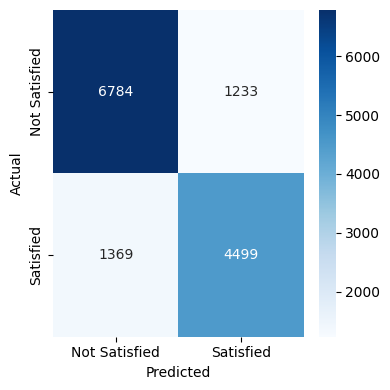

Accuracy:  0.81
Precision: 0.78
Recall: 0.77
F1-Score:  0.78


In [ ]:
#Function to evaluate model performance- confusion matrix,Heat map and classification report
def evaluate(y_test,y_pred):
    cm=confusion_matrix(y_test,y_pred)
    print('Confusion matrix:\n', cm)
    plt.figure(figsize=(4,4))
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['Not Satisfied', 'Satisfied'],
                yticklabels=['Not Satisfied', 'Satisfied'])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()
    precision = precision_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    recall=recall_score(y_test, y_pred)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Accuracy:  {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1-Score:  {f1:.2f}")
#call evaluate function for Logistic regression model
evaluate(y_test,lr_pred)

### Kano Model Analysis

Now, let's perform a Kano Model analysis to understand how different features impact customer satisfaction. We will simulate various levels for each feature, predict the satisfaction probability using our Logistic Regression model, plot the resulting curves, and then classify each feature into 'Must-be', 'One-dimensional', 'Attractive', or 'Indifferent' categories based on the shape of the curve.

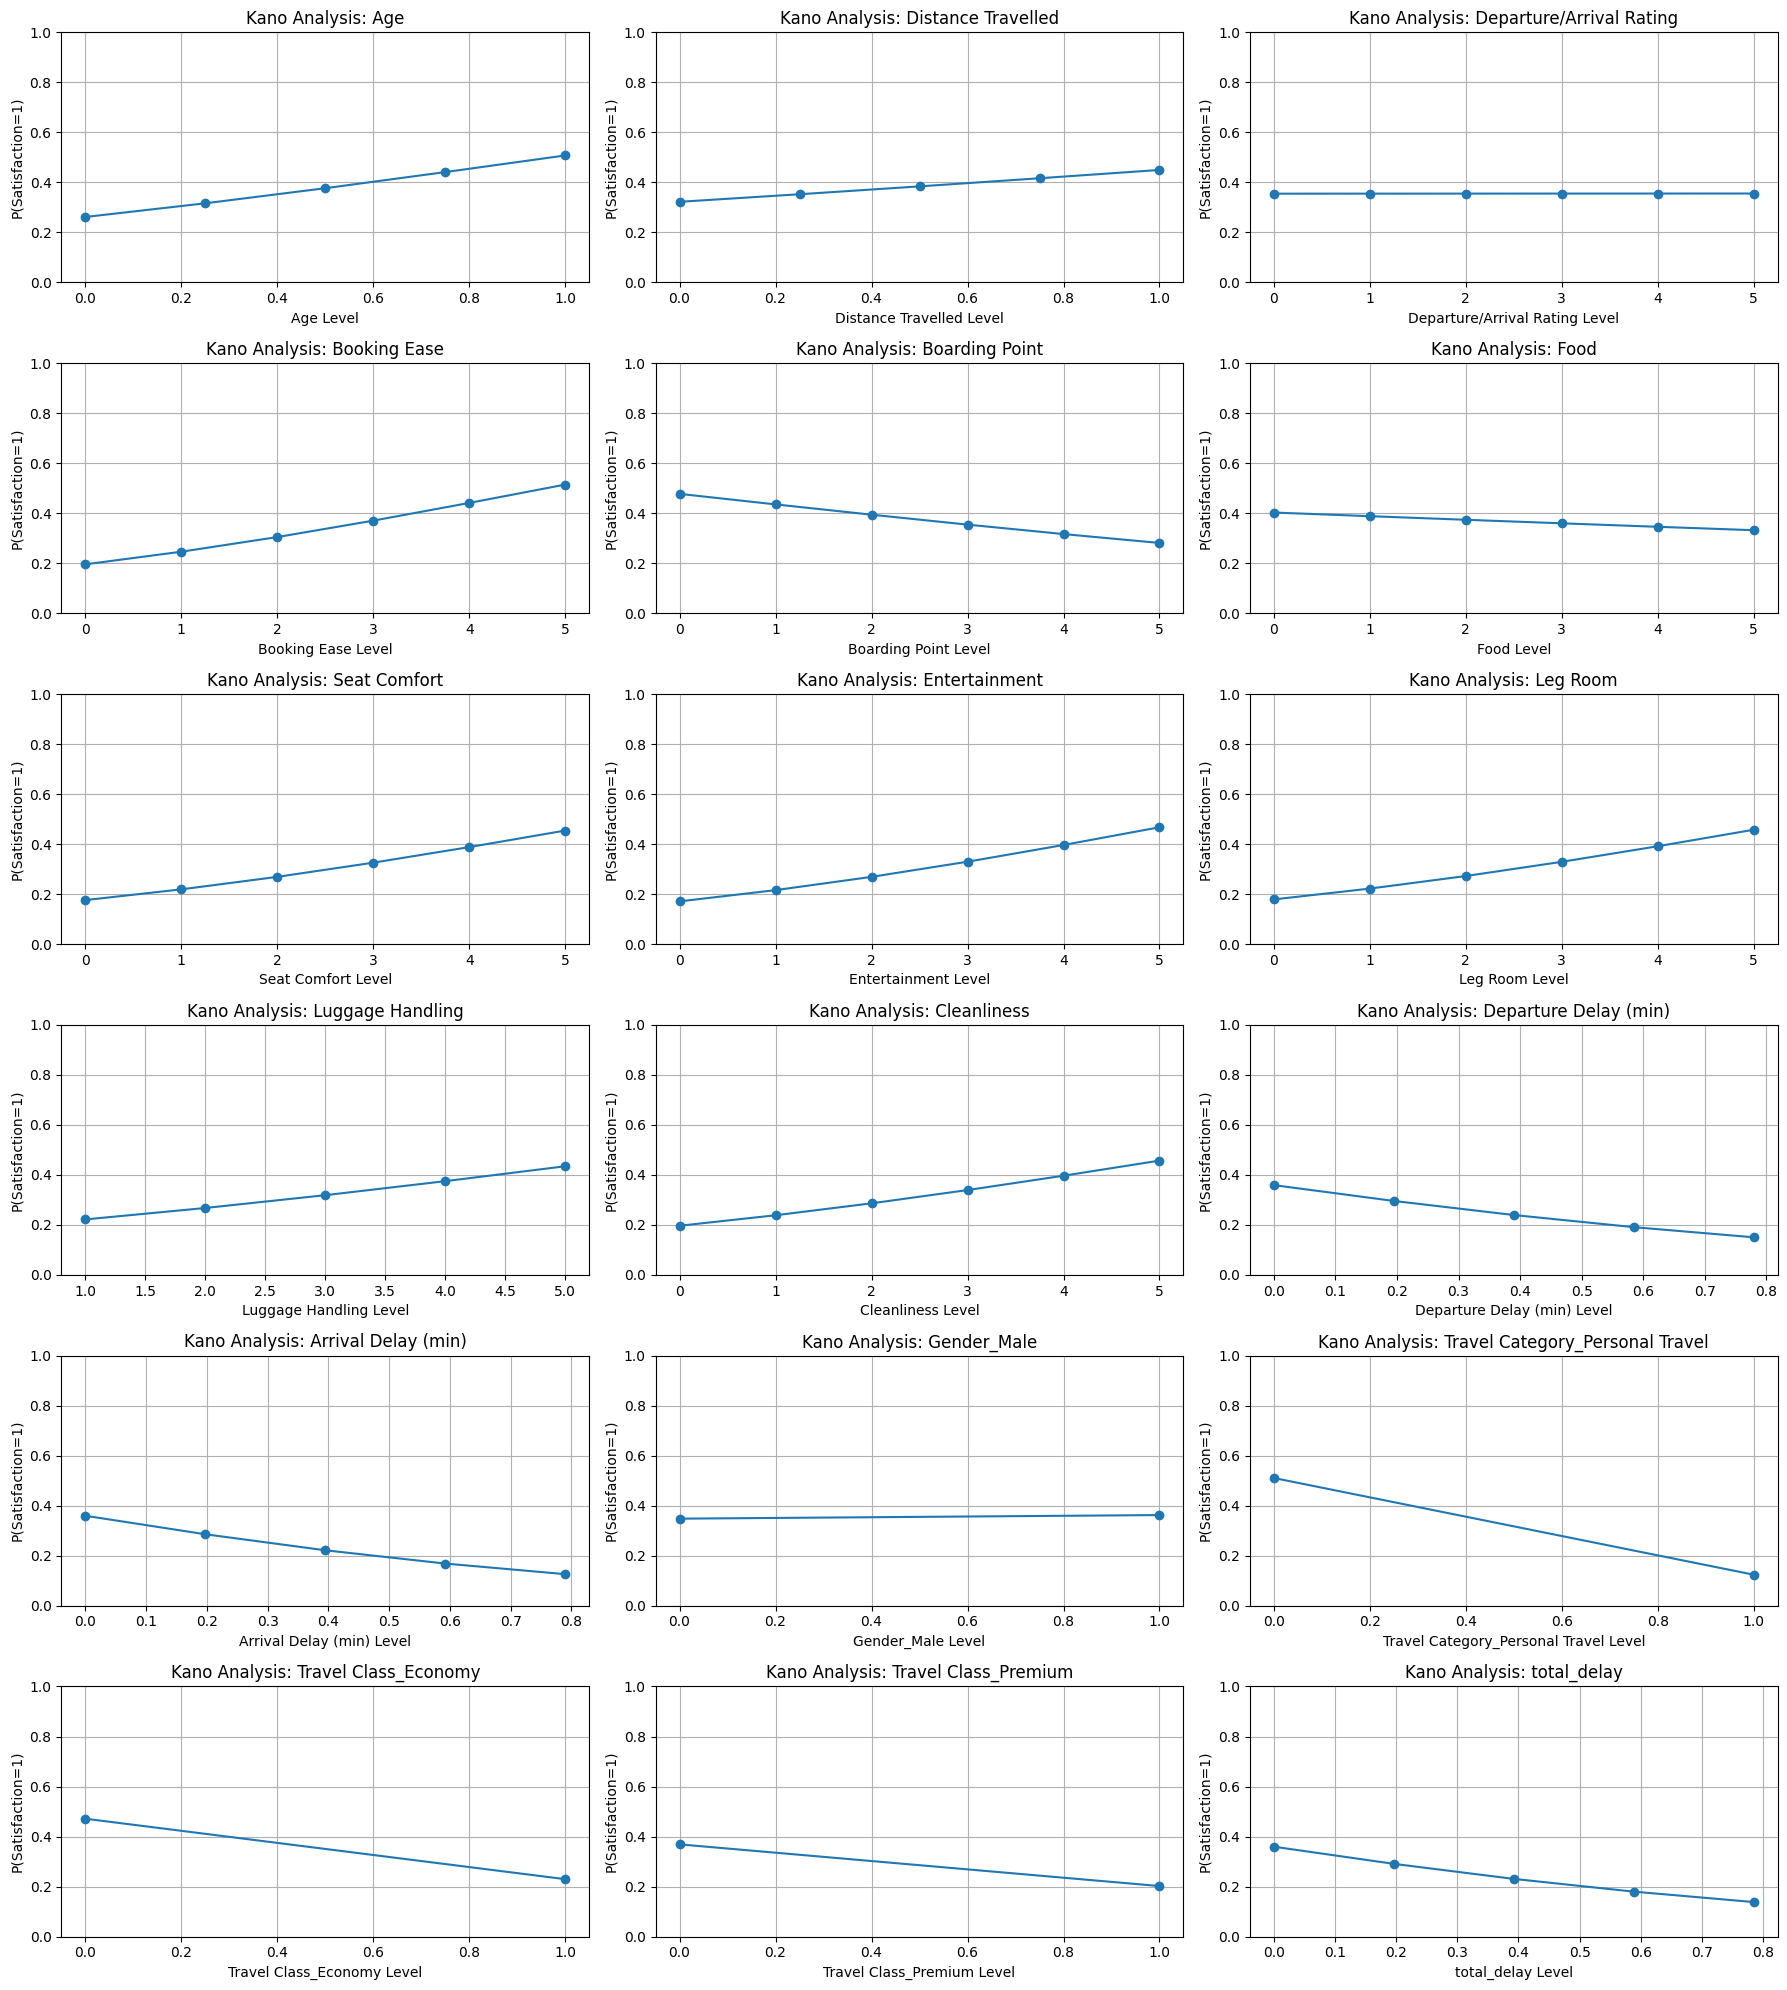


Kano Classification Results:
Age: Other/Complex
Distance Travelled: Indifferent
Departure/Arrival Rating: Indifferent
Booking Ease: Other/Complex
Boarding Point: Indifferent
Food: Indifferent
Seat Comfort: Other/Complex
Entertainment: Other/Complex
Leg Room: Other/Complex
Luggage Handling: Other/Complex
Cleanliness: Other/Complex
Departure Delay (min): Other/Complex
Arrival Delay (min): Other/Complex
Gender_Male: Indifferent
Travel Category_Personal Travel: Other/Complex
Travel Class_Economy: Other/Complex
Travel Class_Premium: Indifferent
total_delay: Other/Complex


In [ ]:
# Define feature types for appropriate range generation
rating_cols = ['Departure/Arrival Rating', 'Booking Ease', 'Boarding Point', 'Food', 'Seat Comfort', 'Entertainment', 'Leg Room', 'Luggage Handling', 'Cleanliness']
binary_cols = ['Gender_Male', 'Travel Category_Personal Travel', 'Travel Class_Economy', 'Travel Class_Premium']
scaled_numerical_cols = ['Age', 'Distance Travelled', 'Departure Delay (min)', 'Arrival Delay (min)', 'total_delay']

kano_results = {}

# Get a baseline (mean) for other features
base_df_mean = x_train.mean().to_frame().T

plt.figure(figsize=(18, 20))
plot_idx = 1

for feature in x_train.columns:
    # Create a temporary DataFrame for the current feature's simulation
    temp_df = base_df_mean.copy()

    feature_values = []
    # Determine the range of values for the current feature
    if feature in binary_cols:
        feature_values = [0, 1]
    elif feature in rating_cols:
        # Ensure we cover the full rating range found in the data
        min_val = int(x_train[feature].min())
        max_val = int(x_train[feature].max())
        feature_values = list(range(min_val, max_val + 1))
        if not feature_values: feature_values = [0,1,2,3,4,5] # Fallback
    elif feature in scaled_numerical_cols:
        feature_values = np.linspace(x_train[feature].min(), x_train[feature].max(), 5).tolist()
    else:
        # Skip 'id' or any other unexpected columns not in x_train.columns
        continue

    predicted_probabilities = []
    for val in feature_values:
        temp_df[feature] = val
        prob_satisfied = log_reg.predict_proba(temp_df)[:, 1][0]
        predicted_probabilities.append(prob_satisfied)

    # Plotting
    plt.subplot(6, 3, plot_idx)
    plt.plot(feature_values, predicted_probabilities, marker='o')
    plt.title(f'Kano Analysis: {feature}')
    plt.xlabel(f'{feature} Level')
    plt.ylabel('P(Satisfaction=1)')
    plt.grid(True)
    plt.ylim(0, 1) # Probability is between 0 and 1

    # Kano classification logic (heuristic)
    if len(feature_values) > 1:
        prob_diff = predicted_probabilities[-1] - predicted_probabilities[0]
        initial_prob = predicted_probabilities[0]

        if prob_diff > 0.6 and initial_prob < 0.3: # Large increase, low start
            kano_type = 'Attractive'
        elif prob_diff > 0.5 and initial_prob >= 0.3: # Significant, more linear increase
            kano_type = 'One-Dimensional'
        elif prob_diff < 0.2 and initial_prob > 0.6: # Small increase, high start
            kano_type = 'Must-Be'
        elif abs(prob_diff) < 0.2: # Very little change
            kano_type = 'Indifferent'
        else:
            kano_type = 'Other/Complex'
    else:
        kano_type = 'N/A (single level)'

    kano_results[feature] = kano_type
    plot_idx += 1

plt.tight_layout()
plt.show()

print("\nKano Classification Results:")
for feature, kano_type in kano_results.items():
    print(f"{feature}: {kano_type}")


In [ ]:
coefficients = pd.DataFrame({
    'Feature': x_train.columns,
    'Coefficient': log_reg.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print(coefficients)

                            Feature  Coefficient
0                               Age     1.068162
1                Distance Travelled     0.541231
3                      Booking Ease     0.294430
7                     Entertainment     0.289775
6                      Seat Comfort     0.272010
8                          Leg Room     0.270862
9                  Luggage Handling     0.247738
10                      Cleanliness     0.247098
13                      Gender_Male     0.062582
2          Departure/Arrival Rating     0.000570
5                              Food    -0.060956
4                    Boarding Point    -0.169701
16             Travel Class_Premium    -0.835910
15             Travel Class_Economy    -1.095922
11            Departure Delay (min)    -1.478591
17                      total_delay    -1.598087
12              Arrival Delay (min)    -1.719917
14  Travel Category_Personal Travel    -1.997410


In [ ]:
# 1. masks for each classes columns
eco_mask = x_train['Travel Class_Economy'] == 1
prem_mask = x_train['Travel Class_Premium'] == 1
bus_mask = (x_train['Travel Class_Economy'] == 0) & (x_train['Travel Class_Premium'] == 0)

# Drop the class columns so the models focus purely on service features
class_cols = ['Travel Class_Economy', 'Travel Class_Premium']

# 2. Subset the data for each class
x_eco, y_eco = x_train[eco_mask].drop(columns=class_cols), y_train[eco_mask]
x_prem, y_prem = x_train[prem_mask].drop(columns=class_cols), y_train[prem_mask]
x_bus, y_bus = x_train[bus_mask].drop(columns=class_cols), y_train[bus_mask]

# 3. Train the dedicated Logistic Regression models
lr_eco = LogisticRegression(max_iter=1000).fit(x_eco, y_eco)
lr_prem = LogisticRegression(max_iter=1000).fit(x_prem, y_prem)
lr_bus = LogisticRegression(max_iter=1000).fit(x_bus, y_bus)

# 4. Compile coefficients into a single comparison DataFrame
class_kano_coefficients = pd.DataFrame({
    'Feature': x_eco.columns,
    'Eco_Coef': lr_eco.coef_[0],
    'Premium_Coef': lr_prem.coef_[0],
    'Business_Coef': lr_bus.coef_[0]
}).sort_values(by='Business_Coef', ascending=False)

print(class_kano_coefficients)

                            Feature  Eco_Coef  Premium_Coef  Business_Coef
0                               Age  0.698773      0.633918       0.988060
1                Distance Travelled -0.519526     -0.302793       0.707044
6                      Seat Comfort  0.077135      0.116992       0.457261
8                          Leg Room  0.082389      0.037291       0.437637
10                      Cleanliness  0.006784      0.143029       0.403566
9                  Luggage Handling  0.049284      0.025508       0.390938
7                     Entertainment  0.285224      0.544107       0.229724
3                      Booking Ease  0.494212      0.177204       0.171248
13                      Gender_Male  0.062354      0.241012       0.047960
2          Departure/Arrival Rating  0.017643      0.028182       0.006768
5                              Food  0.054290      0.018224      -0.066229
4                    Boarding Point -0.207799     -0.126421      -0.115803
11            Departure D

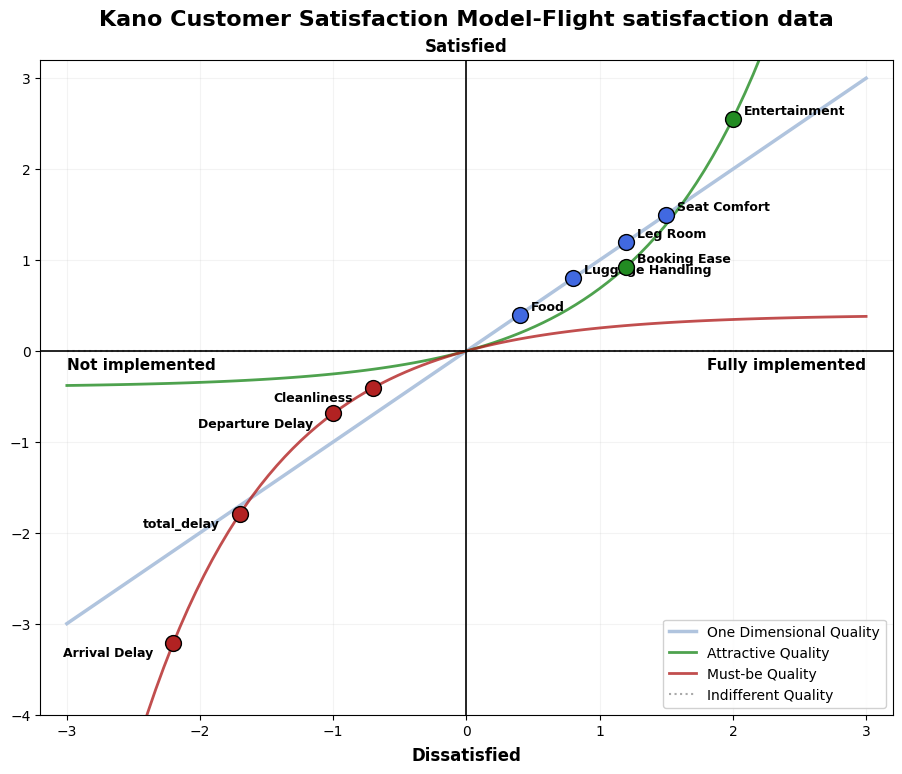

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate the true structural Kano curves
x = np.linspace(-3, 3, 100)
curve_performance = x                               # One-Dimensional (Linear)
curve_delighters = 0.4 * np.exp(x) - 0.4            # Attractive (Curves up on the right)
curve_basic = -0.4 * np.exp(-x) + 0.4               # Basic Needs (Plunges down on the left)
curve_indifferent = np.zeros_like(x)                # Neutral axis

plt.figure(figsize=(11, 8.5))

# Plot baseline structural lines
plt.plot(x, curve_performance, color='lightsteelblue', linewidth=2.5, label='One Dimensional Quality')
plt.plot(x, curve_delighters, color='forestgreen', linewidth=2, alpha=0.8, label='Attractive Quality')
plt.plot(x, curve_basic, color='firebrick', linewidth=2, alpha=0.8, label='Must-be Quality')
plt.plot(x, curve_indifferent, color='darkgray', linestyle=':', linewidth=1.5, label='Indifferent Quality')

# 2. Map actual model features to their true positions on the curves
# (x = execution level/presence, y = satisfaction impact)
features = {
    # Delighters / Attractive (High on the red curve)
    'Entertainment': (2, 0.4 * np.exp(2.0) - 0.4, 'forestgreen'),
    'Booking Ease': (1.2, 0.4 * np.exp(1.2) - 0.4, 'forestgreen'),

    # Performance / One-Dimensional (Distributed along the blue diagonal)
    'Seat Comfort': (1.5, 1.5, 'royalblue'),
    'Leg Room': (1.2, 1.2, 'royalblue'),
    'Luggage Handling': (0.8, 0.8, 'royalblue'),
    'Food': (0.4, 0.4, 'royalblue'),

    # Basic Needs / Must-Be (Low on the green curve due to delay dissatisfaction)
    'Cleanliness': (-0.7, -0.4 * np.exp(0.7) + 0.4, 'firebrick'),
    'Arrival Delay': (-2.2, -0.4 * np.exp(2.2) + 0.4, 'firebrick'),
    'total_delay': (-1.7, -0.4 * np.exp(1.7) + 0.4, 'firebrick'),
    'Departure Delay': (-1.0, -0.4 * np.exp(1.0) + 0.4, 'firebrick')
}

# 3. Plot the data points
for feature, (fx, fy, col) in features.items():
    plt.scatter(fx, fy, color=col, edgecolor='black', s=130, zorder=5)
    # Adjust text placement dynamically to prevent overlapping
    x_offset = 0.08 if fx >= 0 else -0.15
    y_offset = 0.05 if fy >= 0 else -0.15
    ha_align = 'left' if fx >= 0 else 'right'
    plt.text(fx + x_offset, fy + y_offset, feature, fontsize=9, fontweight='bold', ha=ha_align)

# 4. Replicate the reference image axis styling
plt.axhline(0, color='black', linewidth=1.2)
plt.axvline(0, color='black', linewidth=1.2)
plt.xlim(-3.2, 3.2)
plt.ylim(-4, 3.2)

# Text Labels matching the reference image layout
plt.text(0, 3.3, 'Satisfied', fontsize=12, ha='center', fontweight='semibold')
plt.text(0, -4.5, 'Dissatisfied', fontsize=12, ha='center', fontweight='semibold')
plt.text(-3, -0.2, 'Not implemented', fontsize=11, fontweight='semibold', ha='left')
plt.text(3, -0.2, 'Fully implemented', fontsize=11, fontweight='semibold', ha='right')

plt.title('Kano Customer Satisfaction Model-Flight satisfaction data', fontsize=16, pad=25, fontweight='bold')
plt.legend(loc='lower right', framealpha=0.9)
plt.grid(True, alpha=0.15)

plt.savefig('classic_kano_final.png', bbox_inches='tight', dpi=150)
plt.show()